# Derivación numérica

In [ ]:
# Librerías utilizadas en este capítulo
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.differentiate import derivative
from scipy.optimize import curve_fit
# plt.rcParams.update({'font.size': 10, 'figure.dpi': 200})

## Introducción

La *derivada*, $\frac{dy}{dx}$ representa la tasa de cambio de una variable dependiente respecto de una variable independiente. Es una herramienta de uso común en diversas áreas de ingeniería, por ejemplo:

<img src="./images/ejemplos_derivadas.png" width="560" align= center>

En todos estos ejemplos, la variable independiente corresponde a $x$ y la dependiente a $y$.

Ya tenemos dos piezas para aproximar una derivada.

- En la **Unidad 5** truncamos la serie de Taylor y vimos que la diferencia $\left[f(x+h)-f(x)\right]/h$ tiene un error que primero baja con $h$ y luego vuelve a subir por redondeo.

- En la **Unidad 4** construimos un polinomio que pasa por los datos, y un polinomio se puede derivar de forma exacta.



En esta unidad juntamos ambas piezas para obtener fórmulas de derivación con un orden de error conocido, tanto para **funciones conocidas** como para **datos tabulados**, y vemos qué ocurre cuando los datos tienen ruido de medición.

## Diferencias Finitas

### Derivada de primer orden
Matemáticamente, representamos la derivada $f'(x)$ de una función $f(x)$ como:

\begin{equation*}
f'(x) = \lim_{h\rightarrow 0}\frac{f(x+h)-f(x)}{h}
\end{equation*}

En el computador no podemos tomar el límite: usamos un $h$ pequeño pero finito. Para un punto $x_i$ entre dos valores igualmente espaciados $x_{i-1}$ y $x_{i+1}$, con $h = x_i - x_{i-1}$, tenemos tres alternativas para aproximar $f'(x_i)$: hacia atrás (izquierda), hacia adelante (centro) y central (derecha).

<img src="./images/first_order_derivative.png" width="800" align= center>

Esta aproximación se denomina **diferencias finitas**.

Al igual que en la **Unidad 5**, usamos la serie de Taylor para evaluar el error de truncamiento asociado a cada aproximación.

Consideremos la serie de Taylor de $f(x)$ centrada en $x_i$:

\begin{equation*}
f(x) = f(x_i) + f^{\prime}(x_i)(x - x_i) + \frac{f''(x_i)}{2}(x - x_i)^2 + \frac{f'''(x_i)}{6}(x - x_i)^3 + \cdots
\end{equation*}

Evaluando esta expansión en $x_{i-1}$, 

\begin{equation*}
f(x_{i-1})= f(x_i) + f^{\prime}(x_i)(x_{i-1} - x_i) + \frac{f''(x_i)}{2}(x_{i-1} - x_i)^2 + \frac{f'''(x_i)}{6}(x_{i-1} - x_i)^3 + \cdots
\end{equation*}

y despejando $f'(x_i)$, obtenemos la **fórmula de derivada hacia atrás**:

\begin{equation}
f'(x_i) = \frac{f(x_{i}) - f(x_{i-1})}{x_{i} - x_{i-1}} + O(h)
\end{equation}


Similarmente, si evaluamos la expansión en $x_{i+1}$,

\begin{equation*}
f(x_{i+1})= f(x_i) + f^{\prime}(x_i)(x_{i+1} - x_i) + \frac{f''(x_i)}{2}(x_{i+1} - x_i)^2 + \frac{f'''(x_i)}{6}(x_{i+1}- x_i)^3 + \cdots
\end{equation*}

y luego despejamos $f'(x_i)$, obtenemos la **fórmula de derivada hacia adelante**:

\begin{equation}
f'(x_i) = \frac{f(x_{i+1}) - f(x_{i})}{x_{i+1} - x_{i}} + O(h)
\end{equation}

Finalmente, consideremos la diferencia $f(x_{i+1}) - f(x_{i-1})$, con $x_{i+1} - x_i = h$ y $x_{i-1} - x_i = -h$. Los términos pares se cancelan:

\begin{equation*}
f(x_{i+1}) - f(x_{i-1}) = 2h\,f'(x_i) + \frac{2h^3}{3!}f'''(x_i) + \frac{2h^5}{5!}f^{(5)}(x_i) + \cdots
\end{equation*}

Despejando para $f'(x_i)$, obtenemos la **fórmula para derivada central**:

\begin{equation}
f'(x_i) = \frac{f(x_{i+1}) - f(x_{i-1})}{x_{i+1} - x_{i-1}} + O(h^2)
\end{equation}

A partir de este análisis podemos concluir que la derivada central tiene un mayor orden de precisión.

>**Nota puente.** La diferencia central también sale de la **Unidad 4**. El polinomio de interpolación $p_2(x)$ que pasa por $(x_{i-1}, f_{i-1})$, $(x_i, f_i)$ y $(x_{i+1}, f_{i+1})$, derivado en $x_i$, da exactamente $\left(f_{i+1}-f_{i-1}\right)/2h$. **Derivar numéricamente es derivar el interpolante.** La serie de Taylor nos dice cuánto nos equivocamos al hacerlo.

Comprobemos esto con el polinomio del ejemplo 4.4 de Chapra y Canale:

\begin{equation*}
f(x) = -0.1x^4 - 0.15x^3 - 0.5x^2 - 0.25x+1.2
\end{equation*}


en $x = 0.5$ y con $h=0.1$. El valor exacto es $f'(0.5)=-0.9125$.

In [ ]:
# declaramos la función a evaluar
f = lambda x: -0.1*x**4 - 0.15*x**3 - 0.5*x**2 - 0.25*x + 1.2
df_exact = -0.9125 # valor exácto de f'(0.5)

In [ ]:
h = 0.1              # espaciamiento
xi = 0.5             # valor central
x = [xi-h, xi, xi+h] # puntos a evaluar

# diferencias finitas
df_bw = (f(x[1]) - f(x[0]))/(x[1] - x[0]) # hacia atrás
df_fw = (f(x[2]) - f(x[1]))/(x[2] - x[1]) # hacia adelante
df_ct = (f(x[2]) - f(x[0]))/(x[2] - x[0]) # central

In [ ]:
print(f"Hacia atrás:    f'(0.5) = {df_bw:.5f}, error = {abs(df_exact - df_bw):.5f}")
print(f"Hacia adelante: f'(0.5) = {df_fw:.5f}, error = {abs(df_exact - df_fw):.5f}")
print(f"Central:        f'(0.5) = {df_ct:.5f}, error = {abs(df_exact - df_ct):.5f}")

Hacia atrás:    f'(0.5) = -0.82840, error = 0.08410
Hacia adelante: f'(0.5) = -1.00360, error = 0.09110
Central:        f'(0.5) = -0.91600, error = 0.00350


> Con $h=0.1$, las diferencias hacia atrás y hacia adelante se equivocan en ~0.09, del orden de $h$. La diferencia central se equivoca en 0.0035, del orden de $h^2 = 0.01$.

Ahora reduzcamos $h$ desde 1 hasta $10^{-10}$ y grafiquemos el error de las diferencias hacia adelante y central en escala log-log.

In [ ]:
hi = np.logspace(-10, 0, 41)               # h desde 1e-10 hasta 1

# diferencias finitas
diff_fw = (f(xi + hi) - f(xi))/hi          # hacia adelante
diff_bw = (f(xi) - f(xi - hi))/hi          # hacia atrás
diff_ct = (f(xi + hi) - f(xi - hi))/(2*hi) # central

In [ ]:
# error absoluto
error_fw = np.abs(diff_fw - df_exact) # hacia adelante
error_bw = np.abs(diff_bw - df_exact) # hacia atrás
error_ct = np.abs(diff_ct - df_exact) # central

Determinamos el orden $O(h^n)$ asumiendo el modelo $E_\mathrm{abs} = Ah^{n}$.  El exponente $n$ lo obtenemos mediante regresión lineal de $\Rightarrow \log{E_\mathrm{abs}} = n\log h + b$

In [ ]:
# orden del error (pendiente log-log de Error vs h)
k = hi > 1e-3 # zona dominada por truncamiento (h > 1e-3)
n_fw = np.polyfit(np.log(hi[k]), np.log(error_fw[k]), 1)[0]
n_bw = np.polyfit(np.log(hi[k]), np.log(error_bw[k]), 1)[0]
n_ct = np.polyfit(np.log(hi[k]), np.log(error_ct[k]), 1)[0]

Graficamos el error absoluto usando escala log-log (así visualizamos la pendiente). El orden del error lo mostramos con `plt.text(x0, y0, 'texto')`

In [ ]:
%%capture diff_error
plt.figure(figsize=(5, 4))
plt.loglog(hi,error_fw,'o r',label='forward' ,alpha=0.5)
plt.loglog(hi,error_bw,'o b',label='backward' ,alpha=0.5)
plt.loglog(hi,error_ct,'o k',label='central' ,alpha=0.5)

# imprimimos el valor de la pendiente en el gráfico
plt.text(1E-7,1E-5,fr'$\sim h^{{{n_fw:.3f}}}$', color='r')
plt.text(1E-4,1E-5,fr'$\sim h^{{{n_bw:.3f}}}$', color='b')
plt.text(1E-3,1E-7,fr'$\sim h^{{{n_ct:.3f}}}$', color='k')

# graficamos en escala logarítmica para visualizar la pendiente
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Espaciamiento, $h$')
plt.ylabel("Error absoluto")
plt.title("Derivada de $f(x) = -0.1x^4 - 0.15x^3 - 0.5x^2 - 0.25x+1.$")
plt.legend(frameon=False, loc='lower right')
plt.show()

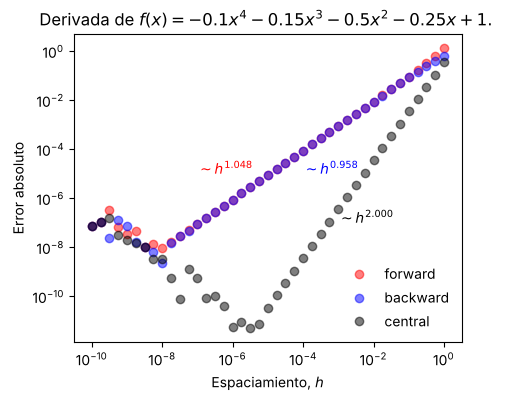

In [ ]:
diff_error()

En la rama derecha recuperamos el orden que predice Taylor: pendiente 1 para la diferencia hacia adelante y 2 para la central. A la izquierda el error vuelve a subir. Es la curva en V de la **Unidad 5**: con $h$ muy chico, $f(x+h)$ y $f(x)$ son casi iguales y su resta pierde cifras significativas. El mínimo de la diferencia central queda cerca de $h=10^{-6}$, y el de la diferencia hacia adelante cerca de $h=10^{-8}$.

### Derivadas de segundo o mayor orden

Mediante un procedimiento similar, podemos generar aproximaciones de diferencias finitas para derivadas de mayor orden.

Por ejemplo, consideremos la suma de las expansiones $f(x_{i+1})$ y $f(x_{i-1})$ centradas en $x_i$,

\begin{equation*}
f(x_{i-1}) + f(x_{i+1}) = 2f(x_i) + h^2f''(x_i) + \frac{h^4f''''(x_i)}{24} + \cdots
\end{equation*}

Despejando para $f''(x_i)$, obtenemos la fórmula para la segunda derivada por diferencia central:

\begin{equation*}
f''(x_i) = \frac{f(x_{i+1}) - 2f(x_i) + f(x_{i-1})}{h^2} + O(h^2)
\end{equation*}

Podemos extender nuestro resultado para determinar fórmulas de diferencias finitas para derivadas de mayor orden. A continuación mostramos un resumen con algunas de estas fórmulas:

**Diferencia hacia adelante**
\begin{align*}
\text{\textbf{Primera derivada}} &&& \text{\textbf{Error}} \\
f'(x_i) &= \dfrac{f(x_{i+1})-f(x_i)}{h} && O(h) \\
f'(x_i) &= \dfrac{-f(x_{i+2})+4f(x_{i+1})-3f(x_i)}{2h} && O(h^2) \\[1em]
\text{\textbf{Segunda derivada}} && \\
f''(x_i) &= \dfrac{f(x_{i+2})-2f(x_{i+1})+f(x_i)}{h^2} && O(h) \\
f''(x_i) &= \dfrac{-f(x_{i+3})+4f(x_{i+2})-5f(x_{i+1})+2f(x_i)}{h^2} && O(h^2) \\[1em]
\text{\textbf{Tercera derivada}} && \\
f'''(x_i) &= \dfrac{f(x_{i+3})-3f(x_{i+2})+3f(x_{i+1})-f(x_i)}{h^3} && O(h) \\
f'''(x_i) &= \dfrac{-3f(x_{i+4})+14f(x_{i+3})-24f(x_{i+2})+18f(x_{i+1})-5f(x_i)}{2h^3} && O(h^2) \\[1em]
\text{\textbf{Cuarta derivada}} && \\
f^{(4)}(x_i) &= \dfrac{f(x_{i+4})-4f(x_{i+3})+6f(x_{i+2})-4f(x_{i+1})+f(x_i)}{h^4} && O(h) \\
f^{(4)}(x_i) &= \dfrac{-2f(x_{i+5})+11f(x_{i+4})-24f(x_{i+3})+26f(x_{i+2})-14f(x_{i+1})+3f(x_i)}{h^4} && O(h^2)
\end{align*}

**Diferencia hacia atrás**
\begin{align*}
\text{\textbf{Primera derivada}} &&& \text{\textbf{Error}} \\
f'(x_i) &= \dfrac{f(x_i)-f(x_{i-1})}{h} && O(h) \\
f'(x_i) &= \dfrac{3f(x_i)-4f(x_{i-1})+f(x_{i-2})}{2h} && O(h^2) \\[1em]
\text{\textbf{Segunda derivada}} && \\
f''(x_i) &= \dfrac{f(x_i)-2f(x_{i-1})+f(x_{i-2})}{h^2} && O(h) \\
f''(x_i) &= \dfrac{2f(x_i)-5f(x_{i-1})+4f(x_{i-2})-f(x_{i-3})}{h^2} && O(h^2) \\[1em]
\text{\textbf{Tercera derivada}} && \\
f'''(x_i) &= \dfrac{f(x_i)-3f(x_{i-1})+3f(x_{i-2})-f(x_{i-3})}{h^3} && O(h) \\
f'''(x_i) &= \dfrac{5f(x_i)-18f(x_{i-1})+24f(x_{i-2})-14f(x_{i-3})+3f(x_{i-4})}{2h^3} && O(h^2) \\[1em]
\text{\textbf{Cuarta derivada}} && \\
f^{(4)}(x_i) &= \dfrac{f(x_i)-4f(x_{i-1})+6f(x_{i-2})-4f(x_{i-3})+f(x_{i-4})}{h^4} && O(h) \\
f^{(4)}(x_i) &= \dfrac{3f(x_i)-14f(x_{i-1})+26f(x_{i-2})-24f(x_{i-3})+11f(x_{i-4})-2f(x_{i-5})}{h^4} && O(h^2)
\end{align*}

**Diferencia central**
\begin{align*}
\text{\textbf{Primera derivada}} &&& \text{\textbf{Error}} \\
f'(x_i) &= \dfrac{f(x_{i+1})-f(x_{i-1})}{2h} && O(h^2) \\
f'(x_i) &= \dfrac{-f(x_{i+2})+8f(x_{i+1})-8f(x_{i-1})+f(x_{i-2})}{12h} && O(h^4) \\[1em]
\text{\textbf{Segunda derivada}} && \\
f''(x_i) &= \dfrac{f(x_{i+1})-2f(x_i)+f(x_{i-1})}{h^2} && O(h^2) \\
f''(x_i) &= \dfrac{-f(x_{i+2})+16f(x_{i+1})-30f(x_i)+16f(x_{i-1})-f(x_{i-2})}{12h^2} && O(h^4) \\[1em]
\text{\textbf{Tercera derivada}} && \\
f'''(x_i) &= \dfrac{f(x_{i+2})-2f(x_{i+1})+2f(x_{i-1})-f(x_{i-2})}{2h^3} && O(h^2) \\
f'''(x_i) &= \dfrac{-f(x_{i+3})+8f(x_{i+2})-13f(x_{i+1})+13f(x_{i-1})-8f(x_{i-2})+f(x_{i-3})}{8h^3} && O(h^4) \\[1em]
\text{\textbf{Cuarta derivada}} && \\
f^{(4)}(x_i) &= \dfrac{f(x_{i+2})-4f(x_{i+1})+6f(x_i)-4f(x_{i-1})+f(x_{i-2})}{h^4} && O(h^2) \\
f^{(4)}(x_i) &= \dfrac{-f(x_{i+3})+12f(x_{i+2})-39f(x_{i+1})+56f(x_i)-39f(x_{i-1})+12f(x_{i-2})-f(x_{i-3})}{6h^4} && O(h^4)
\end{align*}

### Derivadas parciales
Podemos extender las fórmulas de diferencias finitas anteriores para derivadas parciales.

Por ejemplo, utilizando diferencia central en una malla con nodos $(x_i, y_j)$:

\begin{align*}
\frac{\partial f}{\partial x}\bigg|_{ij} &= \frac{f(x_{i+1},y_j) - f(x_{i-1},y_j)}{2\Delta x}+O(\Delta x^2)\\[10pt]
\frac{\partial f}{\partial y}\bigg|_{ij} &= \frac{f(x_i,y_{j+1}) - f(x_i,y_{j-1})}{2\Delta y}+O(\Delta y^2)\\[10pt]
\frac{\partial^2 f}{\partial x^2}\bigg|_{ij} &= \frac{f(x_{i+1},y_j) - 2f(x_i,y_j) + f(x_{i-1},y_j)}{\Delta x^2}+O(\Delta x^2)
\end{align*}

## Diferencias finitas en Python

Podemos clasificar las funciones de derivación de Python en dos tipos:
- Derivación de datos tabulados: `numpy.diff`, `numpy.gradient`, `scipy.interpolate.CubicSpline`.
- Derivación de una función conocida: `scipy.differentiate.derivative`.

### Diferencias finitas con datos tabulados

Consideremos el siguiente set de datos tabulados $x_i$ y $f(x_i)$ correspondientes a la función $f(x) = \sin(x)$.

In [ ]:
# Valores xi tabulados (no igualmente espaciados)
xi = np.array([ 0,  0.72878679,  1.23516778,  2.00081088,  2.77801068, 3.10970675,  3.93589864,  4.14861853,  5.18938779,  5.39179938, 2*np.pi])
# Valores yi = sin(xi) tabulados
yi = np.array([ 0,  0.66596509,  0.94420348,  0.90895968,  0.35562432, 0.0318805 , -0.71337743, -0.84524628, -0.88837681, -0.77794332, 0])

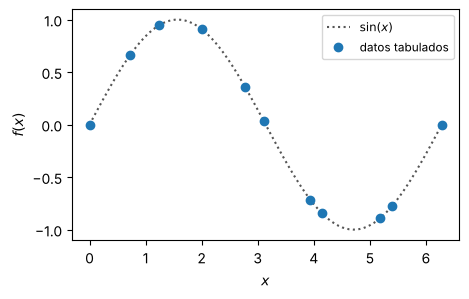

In [ ]:
f = lambda x: np.sin(x)
x = np.linspace(0, 2*np.pi, 100)

plt.figure(figsize=(5, 3))
plt.plot(x, f(x), ':', color='#555555', label='$\\sin(x)$')
plt.plot(xi, yi, 'o', color='#1f77b4', label='datos tabulados')
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.legend(fontsize=8.5)
plt.show()

#### ```numpy.diff```
Esta función determina la diferencia entre 
los dos valores más cercanos en un arreglo.

En otras palabras, para un arreglo `x[0],x[1], ... x[n]`, 

`numpy.diff =  x[1] - x[0], x[2] - x[1], ... , x[n]- x[n-1]`. 

Así, para un arreglo de tamaño $N$, `numpy.diff` entrega un arreglo de tamaño $N-1$.

Si bien la función no entrega la derivada directamente, se puede usar para determinar $f'(x)$ de forma sencilla. Así, para un arreglo de valores `xi`, `yi`, $f'(x)$ se puede determinar por:
```python
dfdx = np.diff(yi)/np.diff(xi) # f'(x)
```

Debido a la forma en la que opera `numpy.diff`, **el resultado corresponde a diferencia hacia adelante o hacia atrás**. Esto dependiendo de como asignemos `dfdx[i]`.

Evaluemos la función `numpy.diff` en nuestro ejemplo con datos tabulados. Comparamos el resultado con el valor exacto $f'(x) = \cos(x)$.

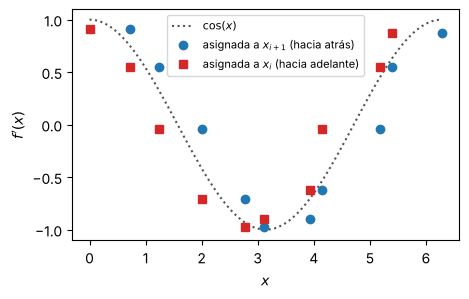

In [ ]:
dfdx = np.diff(yi)/np.diff(xi)    # m datos -> m-1 diferencias

plt.figure(figsize=(5, 3))
plt.plot(x, np.cos(x), ':', color='#555555', label='$\\cos(x)$')
plt.plot(xi[1:], dfdx, 'o', color='#1f77b4', label='asignada a $x_{i+1}$ (hacia atrás)')
plt.plot(xi[:-1], dfdx, 's', color='#d62728', label='asignada a $x_i$ (hacia adelante)')
plt.xlabel('$x$')
plt.ylabel("$f'(x)$")
plt.legend(fontsize=8)
plt.show()

####  ```numpy.gradient```
Esta es una función más optimizada y específica para calcular derivadas. La función `gradient` calcula *directamente* la derivada de una función
 ```python
 dfdx = np.gradient(yi,xi) # f'(x)
 ```

Para los valores interiores, `gradient` **utiliza diferencia central** (adaptada a espaciamiento desigual), y en los extremos diferencia hacia adelante o hacia atrás:
```python
dfdx[0] = (yi[1] - yi[0]  )/(xi[1] - xi[0])    # diferencia hacia adelante
dfdx[n] = (yi[n] - yi[n-1])/(xi[n] - xi[n-1])  # diferencia hacia atrás
```

Así, para un arreglo de tamaño $N$, `numpy.gradient` entrega un arreglo de tamaño $N$.

Evaluemos la función `numpy.gradient` en nuestro ejemplo con datos tabulados. Comparamos el resultado con el valor exacto $f'(x) = \cos(x)$.

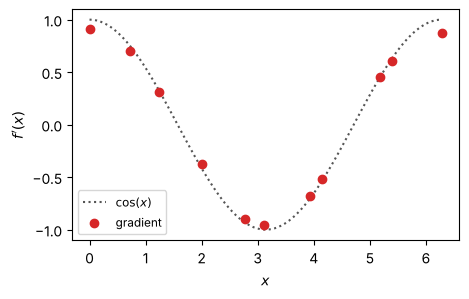

In [ ]:
dfdx = np.gradient(yi, xi)        # m datos -> m derivadas

plt.figure(figsize=(5, 3))
plt.plot(x, np.cos(x), ':', color='#555555', label='$\\cos(x)$')
plt.plot(xi, dfdx, 'o', color='#d62728', label='gradient')
plt.xlabel('$x$')
plt.ylabel("$f'(x)$")
plt.legend(fontsize=8.5)
plt.show()

#### `CubicSpline.derivative`
Una tercera alternativa para determinar la derivada es mediante la función ```CubicSpline``` de ```scipy.interpolate```. A diferencia de ```diff``` y ```gradient```, ```CubicSpline``` permite determinar derivadas de segundo y tercer orden directamente.
```python
from scipy.interpolate import CubicSpline
dfdx  = CubicSpline(xi,yi).derivative(1) # función f'(x)   a partir de spline cúbico
dfdx2 = CubicSpline(xi,yi).derivative(2) # función f''(x)  a partir de spline cúbico
dfdx3 = CubicSpline(xi,yi).derivative(3) # función f'''(x) a partir de spline cúbico
```
> **NOTA** En el ejemplo estamos generando una variable de tipo **callable**. Es decir, si queremos saber $f'(x_i)$ debemos ejecutar ```dfdx(xi)```

Debido a que `CubicSpline` está basada en un polinomio de orden 3, la función aproximada tiene un error del orden $O(h^4)$. Así, la primera derivada de `CubicSpline` tiene un error del orden $O(h^3)$, la segunda $O(h^2)$, y la tercera $O(h)$.

Alternativamente, tal como vimos en la **Unidad 4**, podemos evaluar la derivada directamente con el segundo argumento del spline:
```python
from scipy.interpolate import CubicSpline
y  = CubicSpline(xi, yi) # función f(x) a partir de spline cúbico
dfdx = y(xi, 1)          # f'(xi)
```

Analicemos el ejemplo con datos tabulados usando `CubicSpline`.

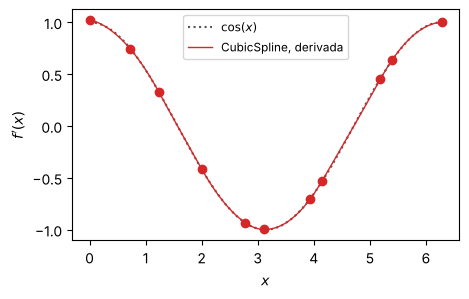

In [ ]:
dfdx = CubicSpline(xi, yi).derivative(1)   # f'(x) como función

plt.figure(figsize=(5, 3))
plt.plot(x, np.cos(x), ':', color='#555555', label='$\\cos(x)$')
plt.plot(x, dfdx(x), '-', color='#d62728', lw=1, label='CubicSpline, derivada')
plt.plot(xi, dfdx(xi), 'o', color='#d62728')
plt.xlabel('$x$')
plt.ylabel("$f'(x)$")
plt.legend(fontsize=8.5)
plt.show()

### Derivada de una función conocida

Si conocemos $f(x)$, podemos elegir $h$. Analicemos la derivada de $f(x)=\sin(x)$ en $x_0 = \pi/3$ con diferencia central, reduciendo $h$ a la mitad cada vez. El valor exacto es $\cos(\pi/3) = 0.5$.

In [ ]:
f = lambda x: np.sin(x)
x0 = np.pi/3
dfdx_exact = 0.5

for h in [0.4, 0.2, 0.1, 0.05]:
    dfdx = (f(x0 + h) - f(x0 - h))/(2*h)   # diferencia central
    print(f'h = {h:.2f}, dfdx = {dfdx:.6f}, error = {abs(dfdx - dfdx_exact):.2e}')

h = 0.40, dfdx = 0.486773, error = 1.32e-02
h = 0.20, dfdx = 0.496673, error = 3.33e-03
h = 0.10, dfdx = 0.499167, error = 8.33e-04
h = 0.05, dfdx = 0.499792, error = 2.08e-04


> Cada vez que $h$ se reduce a la mitad, el error baja a la cuarta parte: es el comportamiento $O(h^2)$.

La función `derivative` de `scipy.differentiate` (SciPy 1.15 o superior) automatiza este procedimiento. Parte de un paso inicial, lo reduce en cada iteración y se detiene cuando dos estimaciones consecutivas coinciden dentro de la tolerancia. Es el mismo criterio que usamos en la **Unidad 7** para decidir si una integral había convergido.
```python
from scipy.differentiate import derivative
res = derivative(f, x0)   # res.df: derivada, res.error: error estimado
```
>**Nota.** `scipy.misc.derivative`, que se utilizó en versiones anteriores del curso, fue eliminada de SciPy en la versión 1.12.

In [ ]:
res = derivative(f, x0)

print(f'dfdx = {res.df:.15f}, error estimado = {res.error:.1e}')
print(f'error real = {abs(res.df - dfdx_exact):.1e}, evaluaciones de f: {res.nfev}')

dfdx = 0.499999999999990, error estimado = 1.3e-12
error real = 1.0e-14, evaluaciones de f: 11


> Con 11 evaluaciones de $f$ obtenemos la derivada con error del orden de $10^{-14}$. `derivative` usa por defecto una fórmula central de orden 8, de la misma familia que las tablas anteriores, y también acepta un arreglo de puntos `x0`.

Más información en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.differentiate.derivative.html).

## Derivar datos medidos

Volvamos al péndulo de la **Unidad 5**. Lo grabamos con una cámara a 100 cuadros por segundo ($h = 0.01$ s), y el seguimiento de video entrega el ángulo $\theta$ con un error de ~0.2°. Queremos la velocidad angular $d\theta/dt$.

Para poder medir el error usamos datos sintéticos: la solución de ángulo pequeño $\theta(t) = 10°\cos(\omega t)$, con $\omega = \sqrt{g/l}$ y $l = 0.3$ m, más ruido normal con desviación estándar de 0.2°.

In [ ]:
g, l = 9.8, 0.3                         # gravedad (m/s2) y largo (m)
w = np.sqrt(g/l)                        # frecuencia angular (rad/s)
dt = 0.01                               # paso de muestreo (s)
ti = np.arange(0, 3 + dt/2, dt)         # tiempos de medición

rng = np.random.default_rng(0)
theta = 10*np.cos(w*ti) + rng.normal(0, 0.2, ti.size)  # ángulo medido (°)
dtheta_exact = -10*w*np.sin(w*ti)                      # velocidad exacta (°/s)

dtheta = np.gradient(theta, ti)
error_rms = np.sqrt(np.mean((dtheta - dtheta_exact)**2))
print(f'Error RMS con gradient: {error_rms:.1f} °/s (amplitud de la velocidad: {10*w:.1f} °/s)')

Error RMS con gradient: 14.3 °/s (amplitud de la velocidad: 57.2 °/s)


Un error de 0.2° en el ángulo produce un error de 14 °/s en la velocidad, un 25 % de la amplitud. Veamos de dónde sale. Cada dato medido es el valor exacto más un error de medición, $\tilde{\theta}_i = \theta_i + e_i$. Reemplazando en la diferencia central:

\begin{equation*}
\frac{\tilde{\theta}_{i+1} - \tilde{\theta}_{i-1}}{2h} = \underbrace{\frac{\theta_{i+1} - \theta_{i-1}}{2h}}_{\theta'(t_i)\, +\, O(h^2)} + \underbrace{\frac{e_{i+1} - e_{i-1}}{2h}}_{\text{error por ruido}}
\end{equation*}

Los errores $e_{i+1}$ y $e_{i-1}$ son independientes y cada uno tiene desviación estándar $\delta$. Al restar dos errores independientes sus varianzas se suman, así que $e_{i+1} - e_{i-1}$ tiene desviación estándar $\sqrt{\delta^2 + \delta^2} = \sqrt{2}\,\delta$. Dividiendo por $2h$:

\begin{equation*}
\sigma_{\theta'} = \frac{\sqrt{2}\,\delta}{2h} = \frac{\delta}{\sqrt{2}\,h} = \frac{0.2}{\sqrt{2}\cdot 0.01} \approx 14 \text{ °/s}
\end{equation*}

Es la misma estructura del error de redondeo de la **Unidad 5**: el error de cada dato queda dividido por $h$. **Al revés que el truncamiento, el error por ruido crece cuando $h$ disminuye.**

Probemos aumentar $h$ usando solo uno de cada `paso` datos:

In [ ]:
for paso in [1, 2, 5, 10]:
    t_s, theta_s = ti[::paso], theta[::paso]
    error_rms = np.sqrt(np.mean((np.gradient(theta_s, t_s) - dtheta_exact[::paso])**2))
    print(f'h = {paso*dt:.2f} s, error RMS = {error_rms:.1f} °/s')

h = 0.01 s, error RMS = 14.3 °/s
h = 0.02 s, error RMS = 7.1 °/s
h = 0.05 s, error RMS = 2.7 °/s
h = 0.10 s, error RMS = 4.1 °/s


El error baja hasta $h = 0.05$ s y vuelve a subir con $h = 0.1$ s, cuando el truncamiento empieza a dominar. Es la curva en V de la **Unidad 5**, con el ruido de medición en el lugar del redondeo. Sin embargo, descartar datos no es la mejor salida.

La alternativa es **ajustar primero y derivar después.** Usemos un `CubicSpline` como modelo de ajuste (**Unidades 3 y 4**): fijamos los nodos $t_k$, tomamos los valores $\theta_k$ del spline en esos nodos como parámetros y los ajustamos con `curve_fit`. Una vez ajustado, derivamos el spline con `.derivative()`.

Con nodos cada 0.15 s, el spline tiene 21 parámetros para ajustar 301 datos.

Error RMS con el spline ajustado: 1.1 °/s


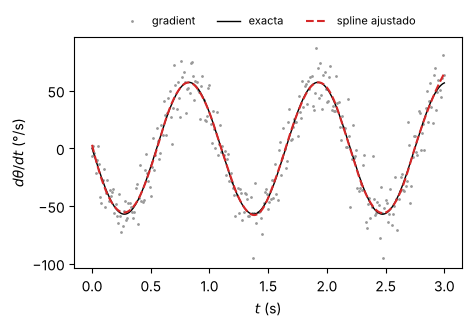

In [ ]:
tk = np.linspace(0, 3, 21)                              # nodos fijos, cada 0.15 s
modelo = lambda t, *thetak: CubicSpline(tk, thetak)(t)  # parámetros: valores en los nodos
thetak, _ = curve_fit(modelo, ti, theta, p0=np.zeros(tk.size))
dtheta_fit = CubicSpline(tk, thetak).derivative()(ti)   # derivada del spline ajustado

error_rms = np.sqrt(np.mean((dtheta_fit - dtheta_exact)**2))
print(f'Error RMS con el spline ajustado: {error_rms:.1f} °/s')

plt.figure(figsize=(5, 3))
plt.plot(ti, np.gradient(theta, ti), '.', ms=2, color='#999999', label='gradient')
plt.plot(ti, dtheta_exact, '-', color='k', lw=1, label='exacta')
plt.plot(ti, dtheta_fit, '--', color='#d62728', label='spline ajustado')
plt.xlabel('$t$ (s)')
plt.ylabel(r'$d\theta/dt$ (°/s)')
plt.legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.show()

El error baja de 14.3 a 1.1 °/s (2 % de la amplitud), usando todos los datos. El número de nodos cumple el papel de $h$: con nodos cada 0.1 s el error sube a 1.5 °/s, porque el spline empieza a seguir el ruido (el sobreajuste de la **Unidad 3**), y con nodos cada 0.25 s sube a 3.8 °/s, porque ya no alcanza a seguir la oscilación.

>**Nota.** SciPy tiene funciones más eficientes para lo mismo:
>- [`savgol_filter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_filter.html) (requiere datos equiespaciados): ajusta un polinomio por mínimos cuadrados en una ventana alrededor de cada dato y lo deriva (error RMS de 1.3 °/s con ventana de 31 datos y polinomio de grado 3).
>- [`make_lsq_spline`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.make_lsq_spline.html): ajusta un spline con nodos fijos por mínimos cuadrados, la misma idea que nuestro ajuste, pero sin optimizador (error RMS de 0.9 °/s).
>- [`make_smoothing_spline`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.make_smoothing_spline.html): ajusta un spline suavizado y elige automáticamente cuánto suavizar (error RMS de 1.7 °/s).

>**Importante.** Integrar promedia los datos y atenúa el ruido, mientras que derivar lo amplifica. Por eso en la **Unidad 7** pudimos integrar datos medidos directamente, y aquí necesitamos suavizar antes de derivar.

## Resumen: ¿qué método uso?

| Situación | Método | En Python |
|---|---|---|
| datos sin ruido | central al interior, adelante/atrás en los bordes | `np.gradient(yi, xi)` |
| datos sin ruido, derivadas de orden superior | derivar el spline cúbico | `CubicSpline(xi, yi).derivative(n)` |
| datos con ruido | ajustar un spline y derivarlo | `curve_fit` + `CubicSpline(tk, yk).derivative()` |
| función conocida | central con paso adaptativo | `derivative(f, x0)` |

Antes de confiar en una derivada numérica conviene revisar:
1. ¿El resultado cambia al duplicar $h$? Si cambia, el truncamiento domina.
2. ¿$h$ es tan chico que el redondeo o el ruido dominan? Graficar la derivada lo delata.
3. ¿Qué pasa en los bordes? Ahí `gradient` usa una fórmula de menor orden.

>**Nota puente.** En la **Unidad 9** el problema se invierte: conocemos la derivada, $dy/dt = F(t,y)$, y buscamos $y$. Reemplazar $dy/dt$ por la diferencia hacia adelante da el método de Euler. La diferencia hacia atrás da Euler implícito y, con la fórmula $O(h^2)$ de la tabla, los métodos BDF que usa `solve_ivp` en problemas rígidos.

## Referencias
- Chapra S., Canale R. **Capítulo 4: Errores de truncamiento y la serie de Taylor** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §4.1 diferenciación numérica (ejemplo 4.4) · §4.3 error numérico total

- Chapra S., Canale R. **Capítulo 23: Diferenciación numérica** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §23.1 fórmulas de alta exactitud · §23.3 datos irregularmente espaciados · §23.4 datos con errores · §23.5 derivadas parciales

- Kong Q., Siauw T., Bayen A. M. **Chapter 20: Numerical Differentiation** in *[Python Programming and Numerical Methods – A Guide for Engineers and Scientists](https://pythonnumericalmethods.berkeley.edu/notebooks/chapter20.00-Numerical-Differentiation.html)*, 1st Ed., Academic Press, 2021.
  - §20.4 derivación con ruido